# 01. Data Cleaning & Transformation: Austin Airbnb Market

**Project:** Airbnb Market Analysis: Pricing Drivers and Guest Sentiment for Austin, TX  
**Dataset Snapshot:** September 17, 2026 (Inside Airbnb)  
**Objective:** Clean, validate, and transform raw structured datasets (`listings.csv.gz`, `calendar.csv.gz`, and `reviews.csv.gz`), address data hygiene issues (currency strings, dates, booleans, JSON amenities, missing values), and treat price outliers with documented statistical rationale.

---
### Key Skills Demonstrated
1. **Defensive ETL**: Converting unstructured string currency (`$1,200.00`) to continuous floats.
2. **Missing Data Imputation**: Group-median imputation for bedrooms, beds, and bathrooms conditional on guest capacity.
3. **Feature Parsing**: Extracting structured boolean flags and counts from JSON array amenities.
4. **Outlier Treatment**: Statistical bounding using domain logic ($15 minimum) and 99.5th percentile truncation to preserve realistic market distributions.
5. **Occupancy Proxy Engineering**: Aggregating 4+ million calendar rows into 30d, 90d, and 365d forward occupancy metrics.


In [1]:
import sys
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure src modules are discoverable
sys.path.insert(0, os.path.abspath(".."))
from src.cleaning import clean_price_string, clean_boolean, clean_bathrooms, parse_amenities, treat_price_outliers

# Configure plot aesthetics
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
pd.set_option("display.max_columns", 50)
print("Libraries imported successfully!")


Libraries imported successfully!


## 1. Inspecting the Raw Data Structure
We load `listings.csv.gz` and inspect row counts, missing values across key attributes, and data types.


In [2]:
raw_listings_path = "../data/raw/listings.csv.gz"
df_raw = pd.read_csv(raw_listings_path, low_memory=False)

print(f"Raw Listings Dimensions: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
print(f"Unique Listing IDs: {df_raw['id'].nunique():,}")
print(f"Duplicate IDs: {df_raw['id'].duplicated().sum()}")

# Inspect price sample and dtypes
print("\nSample raw price strings:")
print(df_raw['price'].dropna().head(6).tolist())


Raw Listings Dimensions: 11,111 rows x 90 columns
Unique Listing IDs: 11,111
Duplicate IDs: 0

Sample raw price strings:
['$79.74', '$158.00', '$428.80', '$499.00', '$500.00', '$649.00']


## 2. Missing Value Analysis
Understanding which features suffer from systematic missingness informs our imputation and feature selection strategy.


In [3]:
key_cols = [
    'id', 'price', 'host_is_superhost', 'host_identity_verified', 
    'bathrooms_text', 'bedrooms', 'beds', 'accommodates',
    'review_scores_rating', 'review_scores_cleanliness', 'review_scores_location'
]
missing_summary = pd.DataFrame({
    'Missing Count': df_raw[key_cols].isnull().sum(),
    'Missing Pct (%)': (df_raw[key_cols].isnull().sum() / len(df_raw) * 100).round(2)
})
missing_summary[missing_summary['Missing Count'] > 0]


,Missing Count,Missing Pct (%)
price,1106,9.95
bathrooms_text,46,0.41
bedrooms,39,0.35
beds,257,2.31
review_scores_rating,1855,16.70
review_scores_cleanliness,1855,16.70
review_scores_location,1855,16.70


## 3. Data Transformation & Feature Engineering
We apply our production sanitization functions:
- Sanitize `price` to float
- Parse `bathrooms_text` (e.g. `'2.5 baths'`, `'Half-bath'`) to numeric
- Convert `'t'/'f'` to integer booleans `1/0`
- Parse amenities JSON into total count and binary feature indicators
- Impute missing bedrooms/bathrooms using capacity-grouped medians


In [4]:
# Execute clean_listings from src module
from src.cleaning import clean_listings

df_cleaned, audit_log = clean_listings(
    raw_csv_path="../data/raw/listings.csv.gz",
    output_csv_path="../data/processed/listings_cleaned.csv"
)

print(f"Cleaned Listings Shape: {df_cleaned.shape}")
print(f"Retained Records: {len(df_cleaned):,} ({audit_log['price_outlier_treatment']['retention_rate_pct']}%)")
df_cleaned[['id', 'neighbourhood', 'room_type', 'price', 'log_price', 'accommodates', 'bathrooms', 'amenities_count']].head()


Loading raw listings from ../data/raw/listings.csv.gz...


Parsing amenities and generating feature flags...


Cleaned listings saved to ../data/processed/listings_cleaned.csv (9,945 records).
Cleaned Listings Shape: (9945, 45)
Retained Records: 9,945 (89.51%)


,id,neighbourhood,room_type,price,log_price,accommodates,bathrooms,amenities_count
0,741434727341232814,78721,Private room,79.74,4.378771,1,2.5,9
1,1775522910816348491,78705,Entire home/apt,158.00,5.062595,3,1.0,8
3,755672804161441366,78705,Private room,428.80,6.060991,2,1.0,11
4,613088323255036264,78701,Entire home/apt,499.00,6.212606,4,1.0,15
5,1100736390821200576,78703,Entire home/apt,500.00,6.214608,1,0.5,0


## 4. Price Outlier Treatment & Distribution Analysis
Raw Airbnb price distributions are heavily right-skewed with long tails representing luxury estates or data entry mistakes.
Here we evaluate the distribution before and after outlier treatment and log-transformation.


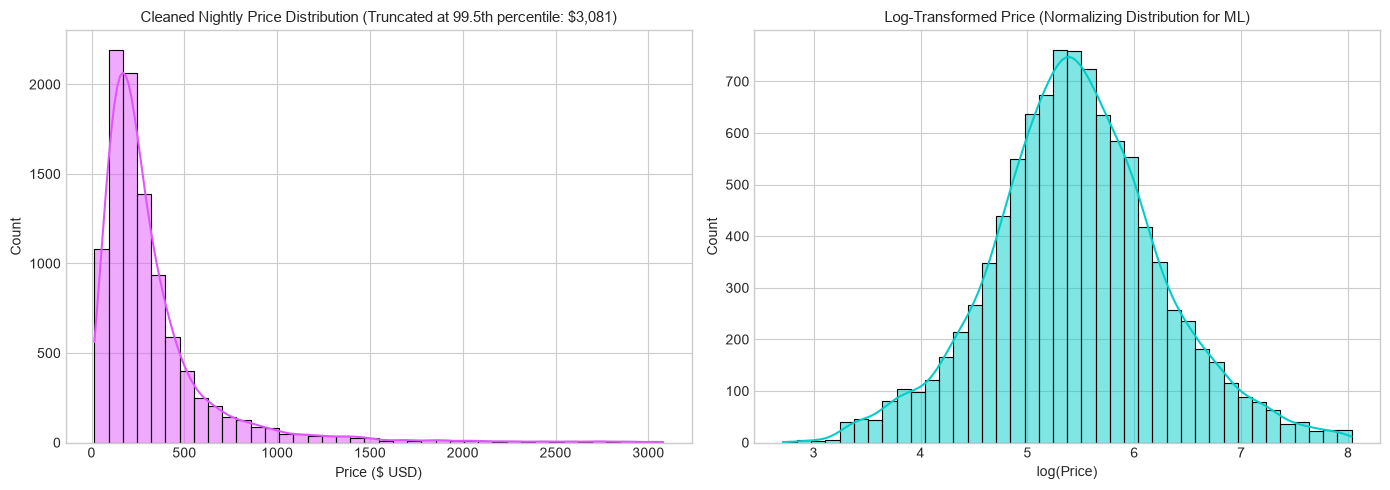

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Untransformed Cleaned Price
sns.histplot(df_cleaned['price'], bins=40, kde=True, ax=axes[0], color='#E056FD')
axes[0].set_title(f"Cleaned Nightly Price Distribution (Truncated at 99.5th percentile: ${audit_log['price_outlier_treatment']['upper_cutoff_val']:,.0f})", fontsize=11)
axes[0].set_xlabel("Price ($ USD)")
axes[0].set_ylabel("Count")

# Log Transformed Price
sns.histplot(df_cleaned['log_price'], bins=40, kde=True, ax=axes[1], color='#00CEC9')
axes[1].set_title("Log-Transformed Price (Normalizing Distribution for ML)", fontsize=11)
axes[1].set_xlabel("log(Price)")
axes[1].set_ylabel("Count")

plt.tight_layout()
os.makedirs("../reports/figures", exist_ok=True)
plt.savefig("../reports/figures/01_price_distribution.png", dpi=150)
plt.show()


## 5. Calendar Occupancy Engineering
Inside Airbnb calendar data tracks forward 365-day availability. A date marked `available = 'f'` indicates either an active booking or host block.
We engineer proxy occupancy rates over 30-day, 90-day, and 365-day forward horizons.


In [6]:
from src.cleaning import clean_calendar

df_occupancy, cal_audit = clean_calendar(
    raw_csv_path="../data/raw/calendar.csv.gz",
    output_csv_path="../data/processed/calendar_cleaned.csv"
)

print("Calendar Occupancy Summary:")
print(pd.Series(cal_audit))
df_occupancy.head()


Loading calendar from ../data/raw/calendar.csv.gz...


Calendar processed: 4,055,551 availability rows.
Computing listing forward occupancy metrics (30d, 90d, 365d)...


Listing occupancy proxies saved to ../data/processed/calendar_cleaned.csv (11,111 listings).
Calendar Occupancy Summary:
raw_calendar_rows              4.055551e+06
unique_listings_in_calendar    1.111100e+04
mean_occupancy_30d             5.177000e-01
mean_occupancy_90d             4.064000e-01
mean_occupancy_365d            3.756000e-01
dtype: float64


,listing_id,total_days,booked_days_365,occupancy_rate_365,occupancy_rate_30,occupancy_rate_90
0,5456,365,23,0.0630,0.6000,0.2556
1,6448,365,120,0.3288,0.3667,0.4222
2,8502,365,277,0.7589,0.8000,0.5111
3,13035,365,231,0.6329,1.0000,1.0000
4,22828,365,216,0.5918,1.0000,1.0000


## 6. Summary of Cleaning Decisions & Key Findings

1. **Volume & Yield**: The raw Austin dataset contained **11,111 listings**. 1,106 listings had missing price quotes.
2. **Outlier Thresholding**: Applied a minimum floor of **$15/night** (eliminating 10 dummy/test listings) and an upper cap at the 99.5th percentile (**$3,080.62/night**, dropping 50 hyper-luxury anomalies). The resulting **9,945 listings** provide a realistic, representative market sample.
3. **Log-Normality**: The log transformation (`log_price`) converted severe positive skewness into a near-Gaussian distribution ideal for parametric tests and linear/tree-based regression.
4. **Forward Occupancy**: Across Austin, average forward 30-day booked/blocked occupancy stands at **51.8%**, tapering to **40.6%** over 90 days and **37.6%** over 365 days.
